In [3]:
import pymupdf as fitz
from pathlib import Path

pdf_path = Path("adbe10kfy25unofficialpdf.pdf")

doc = fitz.open(pdf_path)

pages = []

for page_num, page in enumerate(doc, start=1):
    text = page.get_text("text", sort=True)

    pages.append({
        "page": page_num,
        "text": text
    })

print("Pages:", len(pages))
print("Characters extracted:", sum(len(p["text"]) for p in pages))
print("\n--- Sample: page 3 ---\n")
print(pages[2]["text"][:3000])

Pages: 93
Characters extracted: 364958

--- Sample: page 3 ---

                                                 -78B; E<  EDJ;DJI



 >AF0A3  >>:8=6 'C0C4<4=CB

      8 +..3>398 >9 23=>9<3-+6 3809<7+>398  >23=  88?+6 $/:9<> 98  9<7      -98>+38= F09<A+<. 6995381 =>+>/7/8>=G A3>238
>2/ 7/+8381 90 +::63-+,6/ =/-?<3>3/= 6+A= 38-6?.381 =>+>/7/8>= </6+>/. >9 9?< :<9.?-> ./@/69:7/8> :6+8= +8. 8/A 9< /82+8-/.
900/<381= 9?< ,?=38/== =><+>/1C  +<>303-3+6 38>/6631/8-/ F  G +8. 3889@+>398 797/8>?7 9?< 7+<5/> +8.    9::9<>?83>C +8.
0?>?</ 1<9A>2  7+<5/> +8.    ></8.= 7+-<9/-98973- -98.3>398=  06?->?+>398= 38 09</318 -?<</8-C /B-2+81/ <+>/=  =><+>/13-
38@/=>7/8>= -?=>97/< =?--/== +8. 1<9?:= +8. 38.?=><C :9=3>398381  8 +..3>398 A2/8 ?=/. 38 >23= </:9<> >2/ A9<.= FA366 G
F/B:/->= G F-9?6. G FA9?6. G F7+C G F+8>3-3:+>/= G F38>/8.= G F:6+8= G F,/63/@/= G F=//5= G F>+<1/>= G F/=>37+>/= G F6995=
09< G F6995= >9 G F-98>38?/=G +8. =3736+< /B:</==398= += A/66 += =>+>/7/8>= </1+<.381 9?< 09-?= 09< >2/ 0?>?<

In [4]:
for p in pages[:10]:
    text = p["text"]

    print(
        f"Page {p['page']:>2}: "
        f"{len(text):>5} characters | "
        f"{len(text.split()):>4} words"
    )

    if text.strip():
        print(text[:180].replace("\n", " "))
    else:
        print("[NO TEXT EXTRACTED]")

    print("-" * 80)

Page  1:  5742 characters |  733 words
                         )" (   '( ( '                     '  )& (  ' "  ,   "   #!! '' #"                                               +0B78=6C>=                                 
--------------------------------------------------------------------------------
Page  2:  1547 characters |  158 words
                               #   "                              #&!                                (    #  #"( "('                                                                
--------------------------------------------------------------------------------
Page  3:  5224 characters |  757 words
                                                 -78B; E<  EDJ;DJI     >AF0A3  >>:8=6 'C0C4<4=CB        8 +..3>398 >9 23=>9<3-+6 3809<7+>398  >23=  88?+6 $/:9<> 98  9<7      -98>+3
--------------------------------------------------------------------------------
Page  4:  5820 characters |  784 words
                                                 -78B; E< 

In [5]:
import json

output_path = Path("adobe_10k_extracted.json")

with output_path.open("w", encoding="utf-8") as f:
    json.dump(pages, f, ensure_ascii=False, indent=2)

print(f"Saved to: {output_path.resolve()}")

Saved to: D:\Desktop\IIIT HYD\LMA\LMA assign 1\adobe_10k_extracted.json


In [6]:
from pypdf import PdfReader

pdf_path = "adbe10kfy25unofficialpdf.pdf"
reader = PdfReader(pdf_path)

print("Pages:", len(reader.pages))

for page_num in [2, 3, 4]:
    text = reader.pages[page_num].extract_text() or ""
    print(f"\n--- Page {page_num + 1} ---\n")
    print(text[:1500])

Pages: 93

--- Page 3 ---

>AF0A3 >>:8=6'C0C4<4=CB
8+..3>398>923=>9<3-+63809<7+>398>23=88?+6$/:9<>989 <7-98>+38=F09<A+<.6995381=>+>/7/8>=GA3>238
>2/7/+838190+::63-+,6/=/-?<3>3/=6+A=38-6?.381=>+>/7/8>=</6+>/.>99?<:<9.?->./@/69:7/8>:6+8=+8.8/A9</82+8-/.
900/<381=9?<,?=38/===><+>/1C+<>303-3+638>/6631/8-/F G+8.3889@+>398797/8>?79?<7+<5/>+8.9::9<>?83>C+8.
0?>?</1<9A>27+<5/>+8.></8.=7+-<9/-98973--98.3>398= 06?->?+>398=3809</318-?<</8-C/B-2+81/<+>/==><+>/13-
38@/=>7/8>=-?=>97/<=?--/==+8.1<9?:=+8.38.?=><C:9=3>398 3818+..3>398A2/8?=/.38>23=</:9<>>2/A9<.=FA366G
F/B:/->=GF-9?6.GFA9?6.GF7+CGF+8>3-3:+>/=GF38>/8.=GF:6+8=GF,/63/@/=GF=//5=GF>+<1/>=GF/=>37+>/=GF6995=
09<GF6995=>9GF-98>38?/=G+8.=3736+</B:</==398=+=A/66 +==>+>/7/8>=</1+<.3819?<09-?=09<>2/0?>?</+</1/8/<+66C 
38>/8./.>93./8>30C09<A+<.6995381=>+>/7/8>=+-290>2/09 <A+<.69

In [7]:
import fitz

doc = fitz.open("adbe10kfy25unofficialpdf.pdf")
page = doc[4]  # Page 5

print("Text blocks:")
for block in page.get_text("dict")["blocks"]:
    if "lines" in block:
        for line in block["lines"]:
            text = "".join(
                span["text"] for span in line["spans"]
            )
            if text.strip():
                print(repr(text[:200]))

Text blocks:
"\x15\x1d\x01'CA0C46H"
'\x1a"\x01H;FH;I;DJI\x017\x01=;D;H7J?ED7B\x01EFFEHJKD?JO\x01JE\x01I;HL;\x017D\x01?D9H;7I?D=BO\x01B7H=;\x017D:\x01:?L;HI;\x019KIJEC;H\x01KD?L;HI;\x0c\x01\x1a:E8;[I\x017FFHE79>\x01'
'JE\x01\x1a"\x01?I\x01HEEJ;:\x01?D\x01J>;\x018;B?;<\x01J>7J\x019H;7J?L?JO\x01?I\x017\x01KD?GK;BO\x01>KC7D\x01JH7?J\x01V\x017D:\x01J>7J\x01\x1a"\x01>7I\x01J>;\x01FEM;H\x01JE\x017II?IJ\x017D:\x017CFB?<O\x01>KC7D\x01'
'?D=;DK?JO\x017D:\x01;D>7D9;\x01FHE:K9J?L?JO\x0c\x01\x1a:E8;[I\x01\x1a"\x01B;7:;HI>?F\x018K?B:I\x01ED\x01EKH\x01;NF;HJ?I;\x0179HEII\x019EH;\x019H;7J?L;\x0197J;=EH?;I\x01B?A;\x01?C7=?D=\n\x01'
':;I?=D\n\x01 ?BBKIJH7J?ED\x01 7D:\x01 L?:;E\x01 7I\x01 M;BB\x01 7I\x01 :?=?J7B\x01 :E9KC;DJI\x01 7D:\x01 :?=?J7B\x01 ;NF;H?;D9;I\x0c\x01 (L;H\x01 J>;\x01 F7IJ\x01 I;L;H7B\x01 O;7HI\n\x01 M;\x01 >7L;\x01'
'?D9EHFEH7J;:\x01\x1a"\x01?DJE\x01EKH\x01IEBKJ?EDI\x017D:\x01:;B?L;H;:\x01>KD:H;:I\x01E<\x01\x1a"\x0197F78?B?J?;I\x01JE\x01;D78B;\x019KIJEC;HI\x01JE\x019H;7J;\n\x01MEHA\x01

In [11]:
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"D:\tesseract-OCR\tesseract.exe"
)

print(pytesseract.get_tesseract_version())

5.5.3.20260724


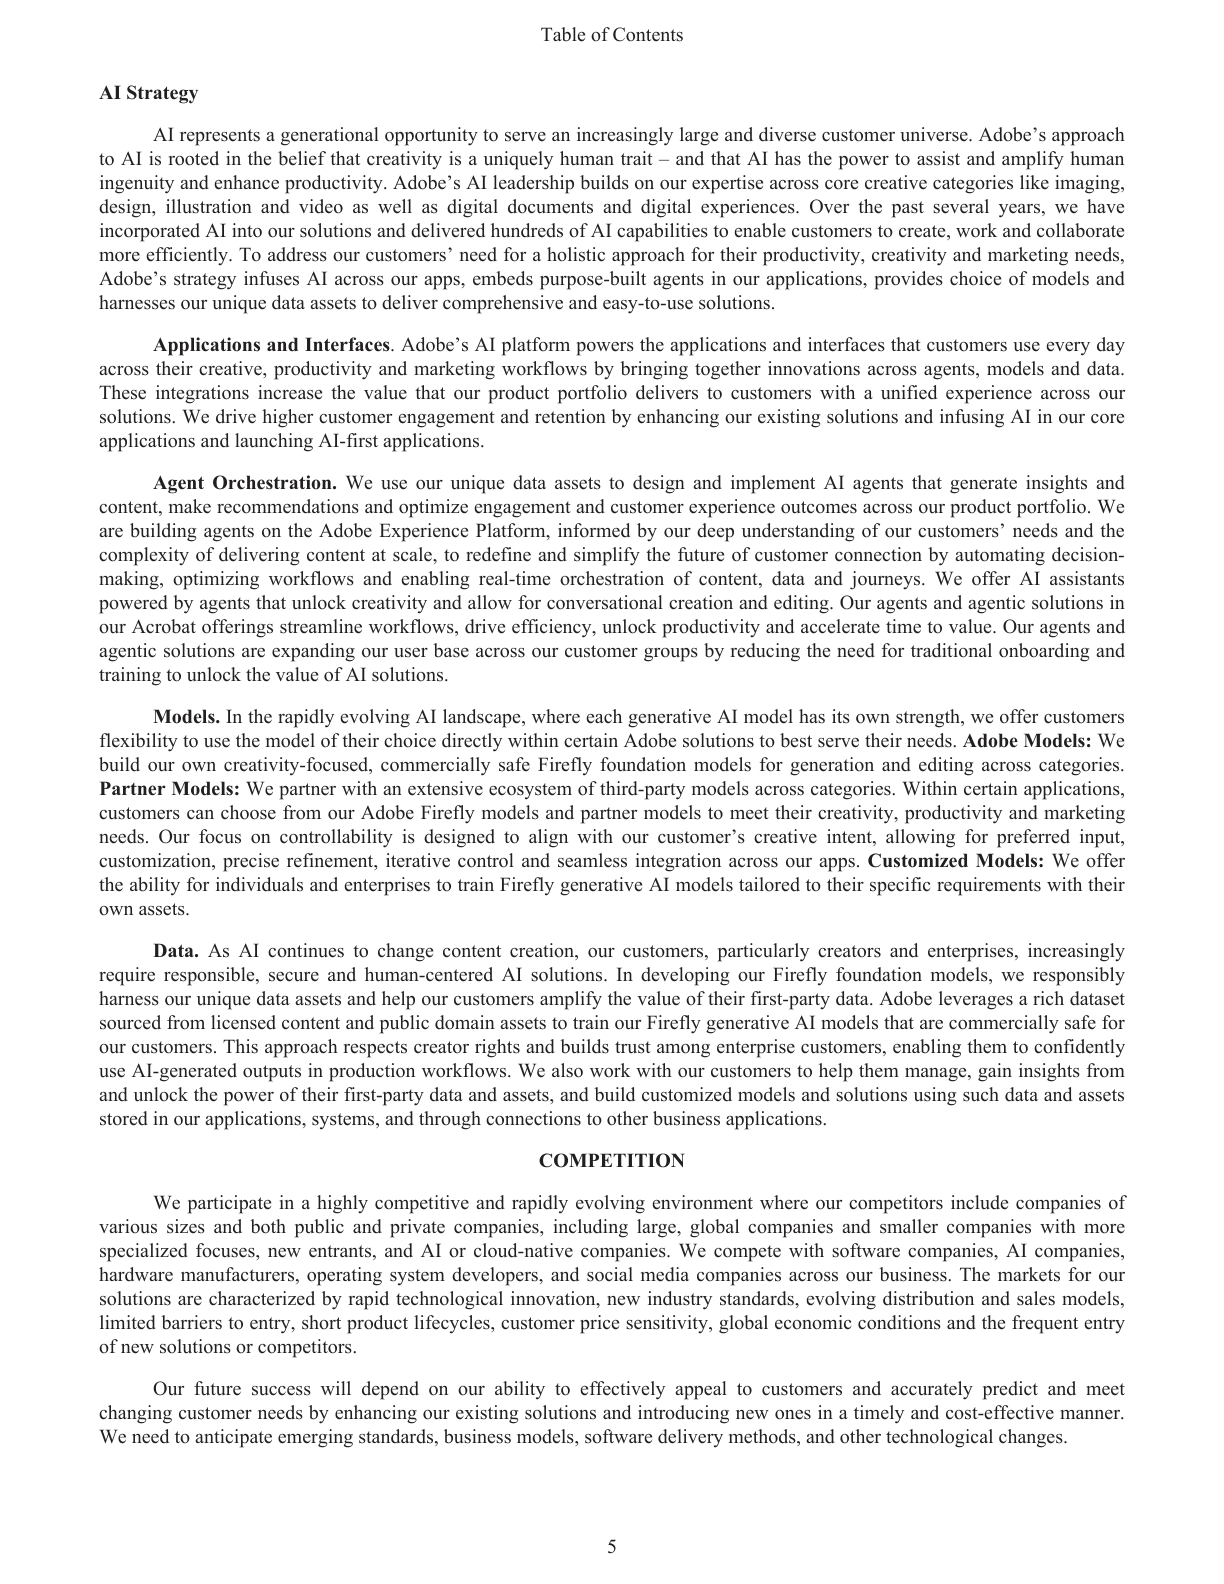

Table of Contents

Al Strategy

Al represents a generational opportunity to serve an increasingly large and diverse customer universe. Adobe’s approach
to AI is rooted in the belief that creativity is a uniquely human trait — and that AI has the power to assist and amplify human
ingenuity and enhance productivity. Adobe’s AI leadership builds on our expertise across core creative categories like imaging,
design, illustration and video as well as digital documents and digital experiences. Over the past several years, we have
incorporated AI into our solutions and delivered hundreds of AI capabilities to enable customers to create, work and collaborate
more efficiently. To address our customers’ need for a holistic approach for their productivity, creativity and marketing needs,
Adobe’s strategy infuses AI across our apps, embeds purpose-built agents in our applications, provides choice of models and
harnesses our unique data assets to deliver comprehensive and easy-to-use solutions.

Ap

In [12]:
import fitz
import pytesseract
from PIL import Image
from IPython.display import display

pdf_path = "adbe10kfy25unofficialpdf.pdf"

doc = fitz.open(pdf_path)
page = doc[4]  # Page 5

# Render at high resolution for OCR.
pix = page.get_pixmap(
    matrix=fitz.Matrix(2, 2),
    alpha=False
)

image = Image.frombytes(
    "RGB",
    [pix.width, pix.height],
    pix.samples
)

display(image)

ocr_text = pytesseract.image_to_string(
    image,
    config="--psm 3"
)

print(ocr_text[:3000])

In [13]:
from pathlib import Path

import fitz
import pytesseract
from PIL import Image

PDF_PATH = Path("adbe10kfy25unofficialpdf.pdf")
OUTPUT_DIR = Path("adobe_10k_extracted")
OUTPUT_DIR.mkdir(exist_ok=True)

# Use your Tesseract installation path.
pytesseract.pytesseract.tesseract_cmd = (
    r"D:\tesseract-OCR\tesseract.exe"
)

doc = fitz.open(PDF_PATH)

print("PDF pages:", len(doc))
print("PDF size:", f"{PDF_PATH.stat().st_size / 1024**2:.2f} MB")

PDF pages: 93
PDF size: 0.54 MB


In [14]:
import json
import time

pages = []
start_time = time.time()

for i, page in enumerate(doc):
    # Render at 300 DPI for better OCR accuracy.
    pix = page.get_pixmap(
        dpi=300,
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    text = pytesseract.image_to_string(
        image,
        lang="eng",
        config="--psm 3"
    )

    record = {
        "page": i + 1,
        "text": text.strip()
    }
    pages.append(record)

    # Save progress after each page so work is recoverable.
    page_file = OUTPUT_DIR / f"page_{i + 1:03d}.txt"
    page_file.write_text(text, encoding="utf-8")

    if (i + 1) % 10 == 0 or i == 0:
        print(
            f"Processed {i + 1}/{len(doc)} pages | "
            f"Characters: {sum(len(p['text']) for p in pages):,} | "
            f"Elapsed: {(time.time() - start_time) / 60:.1f} min"
        )

# Save all extracted text and page metadata together.
with open(OUTPUT_DIR / "pages.json", "w", encoding="utf-8") as f:
    json.dump(pages, f, ensure_ascii=False, indent=2)

print(f"\nCompleted in {(time.time() - start_time) / 60:.1f} minutes.")
print("Saved to:", OUTPUT_DIR.resolve())

Processed 1/93 pages | Characters: 4,676 | Elapsed: 0.1 min
Processed 10/93 pages | Characters: 44,875 | Elapsed: 0.5 min
Processed 20/93 pages | Characters: 94,231 | Elapsed: 1.0 min
Processed 30/93 pages | Characters: 146,960 | Elapsed: 1.4 min
Processed 40/93 pages | Characters: 181,904 | Elapsed: 1.8 min
Processed 50/93 pages | Characters: 209,214 | Elapsed: 2.1 min
Processed 60/93 pages | Characters: 249,757 | Elapsed: 2.5 min
Processed 70/93 pages | Characters: 276,617 | Elapsed: 2.8 min
Processed 80/93 pages | Characters: 307,972 | Elapsed: 3.1 min
Processed 90/93 pages | Characters: 340,222 | Elapsed: 3.5 min

Completed in 3.6 minutes.
Saved to: D:\Desktop\IIIT HYD\LMA\LMA assign 1\adobe_10k_extracted


In [15]:
import json

with open(
    OUTPUT_DIR / "pages.json",
    "r",
    encoding="utf-8"
) as f:
    pages = json.load(f)

print("Pages extracted:", len(pages))
print(
    "Total characters:",
    sum(len(p["text"]) for p in pages)
)

for page_num in [5, 10, 20, 40, 60, 80, 93]:
    item = pages[page_num - 1]
    print(f"\n{'=' * 20} PAGE {item['page']} {'=' * 20}")
    print(item["text"][:700])

Pages extracted: 93
Total characters: 344450

==================== PAGE 5 ====================
Table of Contents

AI Strategy

AI represents a generational opportunity to serve an increasingly large and diverse customer universe. Adobe’s approach
to AI is rooted in the belief that creativity is a uniquely human trait — and that AI has the power to assist and amplify human
ingenuity and enhance productivity. Adobe’s AI leadership builds on our expertise across core creative categories like imaging,
design, illustration and video as well as digital documents and digital experiences. Over the past several years, we have
incorporated AI into our solutions and delivered hundreds of AI capabilities to enable customers to create, work and collaborate
more efficiently. To address our customer

==================== PAGE 10 ====================
Table of Contents

shopping cart to shoppable experiences, with actionable data analysis and automated back-end workflows, native integrations
with other

In [16]:
empty_pages = [
    p["page"] for p in pages
    if len(p["text"].strip()) < 100
]

print("Potentially empty or poorly extracted pages:", empty_pages)

Potentially empty or poorly extracted pages: []


In [17]:
import re

total_chars = sum(len(p["text"]) for p in pages)
total_words = sum(len(p["text"].split()) for p in pages)

print("Pages:", len(pages))
print(f"Total characters: {total_chars:,}")
print(f"Total words: {total_words:,}")

for page_num in [5, 20, 40, 60, 80]:
    text = pages[page_num - 1]["text"]

    print(f"\n--- Page {page_num} ---")
    print(text[:500])

    suspicious = re.findall(
        r"[^\w\s.,;:!?()'\"%$&/-]",
        text
    )
    print("Unusual characters:", len(suspicious))

Pages: 93
Total characters: 344,450
Total words: 51,201

--- Page 5 ---
Table of Contents

AI Strategy

AI represents a generational opportunity to serve an increasingly large and diverse customer universe. Adobe’s approach
to AI is rooted in the belief that creativity is a uniquely human trait — and that AI has the power to assist and amplify human
ingenuity and enhance productivity. Adobe’s AI leadership builds on our expertise across core creative categories like imaging,
design, illustration and video as well as digital documents and digital experiences. Over th
Unusual characters: 8

--- Page 20 ---
Table of Contents

Our ability to acquire other businesses or technologies, make strategic investments or integrate acquired businesses
effectively may also be impaired by adverse economic and political events, including trade tensions, and increased global
scrutiny and evolving regulatory expectations relating to acquisitions and other strategic transactions. We may not be able to
com

In [18]:
chunks = []

CHUNK_SIZE = 500
CHUNK_OVERLAP = 100

for page in pages:
    words = page["text"].split()
    start = 0

    while start < len(words):
        end = min(start + CHUNK_SIZE, len(words))
        chunk_text = " ".join(words[start:end])

        if len(chunk_text.split()) >= 50:
            chunks.append({
                "chunk_id": len(chunks),
                "page": page["page"],
                "text": chunk_text
            })

        if end == len(words):
            break

        start = end - CHUNK_OVERLAP

print("Total chunks:", len(chunks))
print("Average chunk words:", round(
    sum(len(c["text"].split()) for c in chunks) / len(chunks), 1
))

print("\nSample chunk:")
print(chunks[0])

Total chunks: 155
Average chunk words: 370.3

Sample chunk:
{'chunk_id': 0, 'page': 1, 'text': 'UNITED STATES SECURITIES AND EXCHANGE COMMISSION Washington, D.C. 20549 FORM 10-K (Mark One) x} ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the fiscal year ended November 28, 2025 or TRANSITION REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the transition period from to Commission File Number: 000-15175 ADOBE INC. (Exact name of registrant as specified in its charter) Delaware 77-0019522 (State or other jurisdiction of (I.R.S. Employer incorporation or organization) Identification No.) 345 Park Avenue, San Jose, California 95110-2704 (Address of principal executive offices) (408) 536-6000 (Registrant’s telephone number, including area code) Securities registered pursuant to Section 12(b) of the Act: Title of Each Class Trading Symbol Name of Each Exchange on Which Registered Common Stock, $0.0001 par value per sh

In [19]:
import re

clean_pages = []

for page in pages:
    text = page["text"]

    # Remove the repeated running header.
    text = re.sub(
        r"(?im)^\s*Table of Contents\s*$",
        "",
        text
    )

    # Normalize whitespace.
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    text = text.strip()

    clean_pages.append({
        "page": page["page"],
        "text": text
    })

CHUNK_SIZE = 350
CHUNK_OVERLAP = 60

chunks = []

for page in clean_pages:
    words = page["text"].split()
    start = 0

    while start < len(words):
        end = min(start + CHUNK_SIZE, len(words))
        chunk_text = " ".join(words[start:end])

        if len(chunk_text.split()) >= 50:
            chunks.append({
                "chunk_id": len(chunks),
                "page": page["page"],
                "text": chunk_text
            })

        if end == len(words):
            break

        start = end - CHUNK_OVERLAP

print("Pages:", len(clean_pages))
print("Chunks:", len(chunks))
print("Average words per chunk:", round(
    sum(len(c["text"].split()) for c in chunks) / len(chunks),
    1
))
print("\nSample chunk:\n", chunks[0]["text"][:800])

Pages: 93
Chunks: 205
Average words per chunk: 281.2

Sample chunk:
 UNITED STATES SECURITIES AND EXCHANGE COMMISSION Washington, D.C. 20549 FORM 10-K (Mark One) x} ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the fiscal year ended November 28, 2025 or TRANSITION REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the transition period from to Commission File Number: 000-15175 ADOBE INC. (Exact name of registrant as specified in its charter) Delaware 77-0019522 (State or other jurisdiction of (I.R.S. Employer incorporation or organization) Identification No.) 345 Park Avenue, San Jose, California 95110-2704 (Address of principal executive offices) (408) 536-6000 (Registrant’s telephone number, including area code) Securities registered pursuant to Section 12(b) of the Act: Title of Ea
